<a href="https://colab.research.google.com/github/costpetrides/Box_Model/blob/main/Box_Model_Group1_ALL_POINTS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Box Model — Ομάδα 1

**Σχήματα για την εργασία «Ατμοσφαιρική Φυσική και Χημεία»**

Αυτό το notebook δημιουργεί τα σχήματα που ορίζονται στο `ΒΟΧ MODEL_RESULTS_2026.pdf`, από τα CSV του [Box_Model](https://github.com/costpetrides/Box_Model). Δεν αλλάζει τίποτα στο GitHub ούτε στο υπάρχον `Plots.ipynb`.

| Σενάριο | Απαιτούμενα σχήματα |
|:--|:--|
| Βασικό | 1, 2, 3, 4 |
| HV = 0 | 1, 2 |
| LAT = 57° | 1, 2 |
| Mixing layer = 400 m | 1, 3 |
| NOx / 2 | 1, 4 |
| HC / 2 | 1, 4 |
| NOx × 2 | 1, 4 |
| HC × 2 | 1, 4 |

**Ορισμοί**

- Σχ. 1: O₃, NO, NO₂ (O₃ αριστερά, NO/NO₂ δεξιά).
- Σχ. 2: O₃, OH (OH στον δεξιό άξονα).
- Σχ. 3: ALK4, CO (CO στον δεξιό άξονα).
- Σχ. 4: HNO₃.

**Σημαντικό:** Τα όρια των αξόνων υπολογίζονται **μία φορά** ανά τύπο σχήματος, από όλα τα σενάρια που χρησιμοποιούν τον ίδιο τύπο. Έτσι, ο ίδιος ρύπος έχει ίδια κλίμακα σε κάθε συγκρίσιμο σχήμα. Ο χρόνος αποτυπώνεται ως ώρα της ημέρας: `Time / 60`, δηλαδή 06:00–24:00.

**Εκκρεμότητες δεδομένων:** Το `HN 0-Table 1.csv` έχει αντιστοιχιστεί προσωρινά στο HV = 0 και χρειάζεται επιβεβαίωση από την ομάδα. Στο repository υπάρχει `MXconst400-Table 1.csv`, όχι επιβεβαιωμένο αρχείο 800 m. Το notebook δεν επινοεί δεδομένα για τα 800 m.

Μονάδες κατακόρυφων αξόνων: **ppm** (σύμφωνα με τη χρήση των δεδομένων στο υπάρχον Box Model dashboard· ελέγξτε τις μονάδες στο αρχικό μοντέλο πριν την τελική παράδοση).

## 1. Βιβλιοθήκες και ρυθμίσεις

In [ ]:
from pathlib import Path
from urllib.parse import quote
from urllib.request import Request, urlopen
from urllib.error import HTTPError, URLError
from io import StringIO
from zipfile import ZipFile, ZIP_DEFLATED
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import ScalarFormatter, MultipleLocator
from IPython.display import display, Image

# Run the notebook from a clone of the repo (local CSV files), or
# anywhere with internet access (the CSV files are fetched from GitHub).
REPO = "costpetrides/Box_Model"
REF = "main"
DATA_DIR = Path(".")          # Change if the CSV files are stored elsewhere.
OUTPUT_DIR = Path("Box_Model_Group1_Output")
SAVE_PDF = True               # In addition to 300-dpi PNG
MAKE_SLIDE_PANELS = True      # 8 ready-to-place 16:9 slide images
MAKE_O3_COMPARISON = True     # Suggested optional O3 comparison
UNIT = "ppm"                 # Verify with the source model documentation

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "font.size": 10,
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "axes.spines.top": False,
    "figure.facecolor": "white",
    "savefig.facecolor": "white",
    "pdf.fonttype": 42,
    "svg.fonttype": "none",
})

## 2. Σενάρια και απαιτούμενες μεταβλητές

In [ ]:
# File names are taken from the repository (not reconstructed from labels).
# The 800-m case is NOT included: no matching data file was verified.
SCENARIOS = {
    "baseline": {"label": "Βασικό σενάριο", "file": "TESTout1-Table 1.csv", "figures": [1, 2, 3, 4]},
    "hv0":      {"label": "HV = 0 [επιβεβαίωση αρχείου HN 0]", "file": "HN 0-Table 1.csv", "figures": [1, 2]},
    "lat57":    {"label": "LAT = 57°", "file": "LAT 57-Table 1.csv", "figures": [1, 2]},
    "mix400":   {"label": "Mixing layer = 400 m", "file": "MXconst400-Table 1.csv", "figures": [1, 3]},
    "nox_half": {"label": "NOx / 2", "file": "NOX %2-Table 1.csv", "figures": [1, 4]},
    "hc_half":  {"label": "HC / 2", "file": "VOC %2-Table 1.csv", "figures": [1, 4]},
    "nox_x2":   {"label": "NOx × 2", "file": "NOX x2-Table 1.csv", "figures": [1, 4]},
    "hc_x2":    {"label": "HC × 2", "file": "VOC x2-Table 1.csv", "figures": [1, 4]},
}

FIGURES = {
    1: {"title": "O₃, NO, NO₂", "left": ["O3"], "right": ["NO", "NO2"]},
    2: {"title": "O₃, OH", "left": ["O3"], "right": ["OH"]},
    3: {"title": "ALK4, CO", "left": ["ALK4"], "right": ["CO"]},
    4: {"title": "HNO₃", "left": ["HNO3"], "right": []},
}

COLORS = {
    "O3": "#D24B42",    # red
    "NO": "#2867AA",    # blue
    "NO2": "#8053A5",   # purple
    "OH": "#C18D11",    # visible yellow/ochre
    "ALK4": "#278371",  # green
    "CO": "#DA8425",    # orange
    "HNO3": "#515D6B",  # grey
}

CHEM_LABELS = {
    "O3": r"$O_3$", "NO": r"$NO$", "NO2": r"$NO_2$",
    "OH": r"$OH$", "ALK4": "ALK4", "CO": "CO", "HNO3": r"$HNO_3$",
}

REQUIRED_COLUMNS = {"Time"} | {sp for spec in FIGURES.values() for sp in spec["left"] + spec["right"]}
assert sum(len(s["figures"]) for s in SCENARIOS.values()) == 18
print("8 σενάρια • 18 υποχρεωτικά σχήματα • 4 τύποι σχημάτων")

8 σενάρια • 18 υποχρεωτικά σχήματα • 4 τύποι σχημάτων


## 3. Φόρτωση και έλεγχος των πραγματικών CSV

Προτεραιότητα στα τοπικά CSV, εφόσον υπάρχουν. Διαφορετικά, ανάγνωση από το δημόσιο GitHub. Το `sep=";"` και `decimal=","` είναι απαραίτητα για τη σωστή ερμηνεία των αριθμών.

In [ ]:
def read_csv_from_repo(filename):
    local_path = DATA_DIR / filename
    if local_path.is_file():
        df = pd.read_csv(local_path, sep=";", decimal=",", encoding="utf-8-sig")
        return df, str(local_path.resolve())

    url = f"https://raw.githubusercontent.com/{REPO}/{quote(REF, safe='')}/{quote(filename, safe='')}"
    request = Request(url, headers={"User-Agent": "Box-Model-Group1-Notebook"})
    try:
        with urlopen(request, timeout=30) as response:
            raw = response.read().decode("utf-8-sig")
    except (HTTPError, URLError, TimeoutError, OSError) as exc:
        raise RuntimeError(
            f"Δεν κατέστη δυνατή η ανάγνωση του {filename!r}. "
            "Ελέγξτε το internet ή τοποθετήστε τα CSV δίπλα στο notebook. "
            f"URL: {url}"
        ) from exc
    return pd.read_csv(StringIO(raw), sep=";", decimal=","), url


def validate_frame(df, scenario):
    df = df.copy()
    df.columns = df.columns.str.strip()   # First header is "Time " in the CSV.
    if df.columns.duplicated().any():
        raise ValueError(f"{scenario}: διπλές επικεφαλίδες στηλών.")
    missing = sorted(REQUIRED_COLUMNS - set(df.columns))
    if missing:
        raise ValueError(f"{scenario}: λείπουν οι στήλες {missing}.")

    for key in sorted(REQUIRED_COLUMNS):
        df[key] = pd.to_numeric(df[key], errors="raise")
        if not np.isfinite(df[key].to_numpy()).all():
            raise ValueError(f"{scenario}: μη πεπερασμένες τιμές στη στήλη {key}.")

    t = df["Time"].to_numpy(dtype=float)
    if len(t) < 2 or np.any(np.diff(t) <= 0):
        raise ValueError(f"{scenario}: ο χρόνος δεν είναι αυστηρά αύξων.")
    for key in REQUIRED_COLUMNS - {"Time"}:
        if (df[key] < -1e-12).any():
            raise ValueError(f"{scenario}: αρνητικές συγκεντρώσεις στη στήλη {key}.")

    df["Hour"] = df["Time"] / 60.0
    return df


data = {}
sources = {}
for scenario_id, spec in SCENARIOS.items():
    frame, source = read_csv_from_repo(spec["file"])
    data[scenario_id] = validate_frame(frame, scenario_id)
    sources[scenario_id] = source

# All eight runs must be aligned in clock time before comparisons.
base_times = data["baseline"]["Time"].to_numpy()
for scenario_id, df in data.items():
    if not np.array_equal(df["Time"].to_numpy(), base_times):
        raise ValueError(f"{scenario_id}: διαφορετικό χρονικό πλέγμα από το βασικό σενάριο.")

# Actual snapshot checked: 19 points, once per hour, 06:00–24:00.
expected_times = np.arange(360, 1441, 60)
if not np.array_equal(base_times, expected_times):
    warnings.warn("Το χρονικό πλέγμα διαφέρει από το επαληθευμένο 06:00–24:00 ανά 1 ώρα.")

summary = pd.DataFrame([
    {"Σενάριο": SCENARIOS[k]["label"], "Εγγραφές": len(v),
     "Από (h)": v["Hour"].iloc[0], "Έως (h)": v["Hour"].iloc[-1],
     "Πηγή": sources[k]}
    for k, v in data.items()
])
display(summary[["Σενάριο", "Εγγραφές", "Από (h)", "Έως (h)"]])
print("Έλεγχος: όλα τα CSV διαβάστηκαν και έχουν συμβατό χρονικό πλέγμα.")

,Σενάριο,Εγγραφές,Από (h),Έως (h)
0,Βασικό σενάριο,19,6.0,24.0
1,HV = 0 [επιβεβαίωση αρχείου HN 0],19,6.0,24.0
2,LAT = 57°,19,6.0,24.0
3,Mixing layer = 400 m,19,6.0,24.0
4,NOx / 2,19,6.0,24.0
5,HC / 2,19,6.0,24.0
6,NOx × 2,19,6.0,24.0
7,HC × 2,19,6.0,24.0


Έλεγχος: όλα τα CSV διαβάστηκαν και έχουν συμβατό χρονικό πλέγμα.


## 4. Κοινές κλίμακες ανά τύπο σχήματος

Για κάθε Σχ. 1–4, βρίσκουμε το μεγαλύτερο μέγεθος από τα σενάρια όπου ζητείται το συγκεκριμένο σχήμα. Οι δύο άξονες έχουν ανεξάρτητα αλλά σταθερά όρια. Έτσι δεν συγκρίνουμε διαγράμματα με διαφορετικές κλίμακες χωρίς να το καταλαβαίνουμε.

In [ ]:
def rounded_upper(value):
    """Upper bound above data, rounded to a legible positive number."""
    if not np.isfinite(value) or value <= 0:
        return 1.0
    x = value * 1.08
    power = 10.0 ** np.floor(np.log10(x))
    normalized = x / power
    choices = np.array([1, 1.2, 1.25, 1.5, 2, 2.5, 3, 3.5, 4, 5, 6, 7, 8, 10])
    return float(choices[np.searchsorted(choices, normalized)] * power)


def limits_for_figure(figure_no):
    selected = [k for k, sc in SCENARIOS.items() if figure_no in sc["figures"]]
    spec = FIGURES[figure_no]
    result = {}
    for axis_name in ("left", "right"):
        species = spec[axis_name]
        if species:
            max_y = max(float(data[k][sp].max()) for k in selected for sp in species)
            result[axis_name] = (0.0, rounded_upper(max_y))
    return result


SCALES = {number: limits_for_figure(number) for number in FIGURES}
for figure_no, scales in SCALES.items():
    print(f"Σχ. {figure_no}: {scales}")

Σχ. 1: {'left': (0.0, 0.4), 'right': (0.0, 0.15000000000000002)}
Σχ. 2: {'left': (0.0, 0.12), 'right': (0.0, 1e-06)}
Σχ. 3: {'left': (0.0, 0.02), 'right': (0.0, 0.35000000000000003)}
Σχ. 4: {'left': (0.0, 0.07)}


## 5. Ενιαία συνάρτηση σχεδίασης

Χρησιμοποιούνται σταθερά χρώματα ανά χημική ουσία, σημειοδείκτες στις μετρήσεις και επιστημονική σημειογραφία για πολύ μικρές συγκεντρώσεις, ειδικά για OH.
Κάθε ένα από τα 19 χρονικά σημεία σημειώνεται με marker σε κάθε καμπύλη (`markevery=1`). Δεν γίνεται δειγματοληψία, λείανση ή παρεμβολή των δεδομένων.


In [ ]:
def draw_on_axis(ax, df, figure_no, compact=False):
    spec = FIGURES[figure_no]
    scales = SCALES[figure_no]
    x = df["Hour"].to_numpy()
    handles = []
    plot_kwargs = {"linewidth": 1.9 if compact else 2.2,
                   "marker": "o", "markersize": 2.9 if compact else 3.6,
                   "markevery": 1, "zorder": 3}

    for sp in spec["left"]:
        (line,) = ax.plot(x, df[sp].to_numpy(), color=COLORS[sp],
                          label=CHEM_LABELS[sp], **plot_kwargs)
        handles.append(line)
    ax.set_ylim(*scales["left"])
    ax.set_ylabel(f"{', '.join(spec['left'])} [{UNIT}]" if len(spec["left"]) > 1 else
                  f"{spec['left'][0]} [{UNIT}]")
    ax.set_xlabel("Ώρα ημέρας [h]")
    ax.set_xlim(float(x.min()), float(x.max()))
    ax.xaxis.set_major_locator(MultipleLocator(3))
    ax.grid(True, color="#B9C0C8", alpha=0.4, linewidth=0.7)
    ax.set_axisbelow(True)
    ax.spines["right"].set_visible(False)

    if spec["right"]:
        ax2 = ax.twinx()
        for sp in spec["right"]:
            (line,) = ax2.plot(x, df[sp].to_numpy(), color=COLORS[sp],
                               label=CHEM_LABELS[sp], **plot_kwargs)
            handles.append(line)
        ax2.set_ylim(*scales["right"])
        ax2.set_ylabel(f"{', '.join(spec['right'])} [{UNIT}]")
        ax2.spines["top"].set_visible(False)
        ax2.grid(False)
        if "OH" in spec["right"]:
            formatter = ScalarFormatter(useMathText=True)
            formatter.set_powerlimits((0, 0))
            ax2.yaxis.set_major_formatter(formatter)
        return handles
    return handles


def make_figure(scenario_id, figure_no):
    scenario = SCENARIOS[scenario_id]
    fig, ax = plt.subplots(figsize=(9, 4.9))
    handles = draw_on_axis(ax, data[scenario_id], figure_no)
    fig.suptitle(f"{scenario['label']}  |  Σχ. {figure_no}: {FIGURES[figure_no]['title']}",
                 y=0.975, fontsize=13)
    fig.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, 0.91),
               frameon=False, ncol=len(handles), fontsize=11)
    fig.subplots_adjust(left=0.11, right=0.87, bottom=0.15, top=0.77)
    return fig

## 6. Δημιουργία των 18 υποχρεωτικών σχημάτων

Κάθε σχήμα αποθηκεύεται σε **PNG 300 dpi**, και προαιρετικά σε διανυσματικό PDF. Τα ονόματα περιέχουν το σενάριο και τον αριθμό σχήματος.

In [ ]:
FIGURES_DIR = OUTPUT_DIR / "01_required_figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

manifest = []
for scenario_id, scenario in SCENARIOS.items():
    for figure_no in scenario["figures"]:
        fig = make_figure(scenario_id, figure_no)
        stem = f"{scenario_id}_Fig{figure_no}"
        png = FIGURES_DIR / f"{stem}.png"
        fig.savefig(png, dpi=300, bbox_inches="tight")
        if SAVE_PDF:
            fig.savefig(FIGURES_DIR / f"{stem}.pdf", bbox_inches="tight")
        plt.close(fig)
        manifest.append({
            "scenario": scenario_id,
            "label": scenario["label"],
            "source_csv": scenario["file"],
            "figure": figure_no,
            "species": ", ".join(FIGURES[figure_no]["left"] + FIGURES[figure_no]["right"]),
            "png": str(png),
        })

manifest_df = pd.DataFrame(manifest)
assert len(manifest_df) == 18, "Δεν παρήχθησαν 18 απαιτούμενα σχήματα."
manifest_df.to_csv(OUTPUT_DIR / "figure_manifest.csv", index=False, encoding="utf-8-sig")
print(f"Ολοκληρώθηκαν {len(manifest_df)} υποχρεωτικά σχήματα στον φάκελο {FIGURES_DIR}.")
display(manifest_df[["label", "figure", "species"]])

Ολοκληρώθηκαν 18 υποχρεωτικά σχήματα στον φάκελο Box_Model_Group1_Output/01_required_figures.
Ολοκληρώθηκαν 18 υποχρεωτικά σχήματα στον φάκελο Box_Model_Group1_Output/01_required_figures.


,label,figure,species
0,Βασικό σενάριο,1,"O3, NO, NO2"
1,Βασικό σενάριο,2,"O3, OH"
2,Βασικό σενάριο,3,"ALK4, CO"
3,Βασικό σενάριο,4,HNO3
4,HV = 0 [επιβεβαίωση αρχείου HN 0],1,"O3, NO, NO2"
5,HV = 0 [επιβεβαίωση αρχείου HN 0],2,"O3, OH"
6,LAT = 57°,1,"O3, NO, NO2"
7,LAT = 57°,2,"O3, OH"
8,Mixing layer = 400 m,1,"O3, NO, NO2"
9,Mixing layer = 400 m,3,"ALK4, CO"


,label,figure,species
0,Βασικό σενάριο,1,"O3, NO, NO2"
1,Βασικό σενάριο,2,"O3, OH"
2,Βασικό σενάριο,3,"ALK4, CO"
3,Βασικό σενάριο,4,HNO3
4,HV = 0 [επιβεβαίωση αρχείου HN 0],1,"O3, NO, NO2"
5,HV = 0 [επιβεβαίωση αρχείου HN 0],2,"O3, OH"
6,LAT = 57°,1,"O3, NO, NO2"
7,LAT = 57°,2,"O3, OH"
8,Mixing layer = 400 m,1,"O3, NO, NO2"
9,Mixing layer = 400 m,3,"ALK4, CO"


## 7. Εικόνες 16:9 για τις οκτώ διαφάνειες

Κάθε εικόνα περιέχει μόνο τα σχήματα που ζητήθηκαν για το συγκεκριμένο σενάριο. Το βασικό σενάριο έχει διάταξη 2×2· τα υπόλοιπα 1×2. Δεν δημιουργείται αρχείο PowerPoint: οι εικόνες μπορούν να μπουν απευθείας στις διαφάνειες.

In [ ]:
SLIDES_DIR = OUTPUT_DIR / "02_slide_panels"
if MAKE_SLIDE_PANELS:
    SLIDES_DIR.mkdir(parents=True, exist_ok=True)
    for scenario_id, scenario in SCENARIOS.items():
        figure_numbers = scenario["figures"]
        nrows, ncols = (2, 2) if len(figure_numbers) == 4 else (1, 2)
        fig, axes = plt.subplots(nrows, ncols, figsize=(16, 9))
        axes = np.atleast_1d(axes).ravel()
        for ax, number in zip(axes, figure_numbers):
            handles = draw_on_axis(ax, data[scenario_id], number, compact=True)
            ax.set_title(f"Σχ. {number} — {FIGURES[number]['title']}", pad=13)
            ax.legend(handles=handles, loc="upper left", frameon=True,
                      framealpha=0.94, facecolor="white", edgecolor="#E1E4E8",
                      fontsize=9, ncol=1 if len(handles) == 1 else len(handles))
        fig.suptitle(scenario["label"], fontsize=19, y=0.974)
        if nrows == 2:
            fig.subplots_adjust(left=0.075, right=0.925, top=0.88,
                                bottom=0.095, wspace=0.34, hspace=0.45)
        else:
            fig.subplots_adjust(left=0.075, right=0.925, top=0.84,
                                bottom=0.19, wspace=0.34)
        fig.savefig(SLIDES_DIR / f"slide_{scenario_id}.png", dpi=180)
        plt.close(fig)
    print(f"Δημιουργήθηκαν {len(SCENARIOS)} εικόνες διαφανειών στον φάκελο {SLIDES_DIR}.")

Δημιουργήθηκαν 8 εικόνες διαφανειών στον φάκελο Box_Model_Group1_Output/02_slide_panels.
Δημιουργήθηκαν 8 εικόνες διαφανειών στον φάκελο Box_Model_Group1_Output/02_slide_panels.


## 8. Προαιρετικό συγκριτικό σχήμα O₃

Στο PDF προτείνεται επίσης να παρουσιαστεί ένας ρύπος μόνος του σε πολλά σενάρια. Εδώ συγκρίνουμε το O₃ και στα οκτώ διαθέσιμα σενάρια μαζί με το βασικό. Το σχήμα αυτό **δεν** προσμετράται στα 18 υποχρεωτικά.
Όλες οι καμπύλες εμφανίζουν markers στα 19 διαθέσιμα χρονικά σημεία.


In [ ]:
OPTIONAL_DIR = OUTPUT_DIR / "03_optional_comparison"
if MAKE_O3_COMPARISON:
    OPTIONAL_DIR.mkdir(parents=True, exist_ok=True)
    fig, ax = plt.subplots(figsize=(10.6, 5.4))
    scenario_colors = ["#202833", "#6D7380", "#2867AA", "#278371",
                       "#D24B42", "#C18D11", "#8053A5", "#DA8425"]
    for (scenario_id, scenario), color in zip(SCENARIOS.items(), scenario_colors):
        df = data[scenario_id]
        ax.plot(df["Hour"], df["O3"], label=scenario["label"],
                color=color, linewidth=2.6 if scenario_id == "baseline" else 1.7,
                linestyle="--" if scenario_id == "baseline" else "-",
                marker="o", markevery=1, markersize=2.6)
    ax.set(xlim=(6, 24), ylim=SCALES[1]["left"],
           xlabel="Ώρα ημέρας [h]", ylabel=f"O₃ [{UNIT}]",
           title="Σύγκριση O₃ μεταξύ των σεναρίων — Ομάδα 1")
    ax.xaxis.set_major_locator(MultipleLocator(3))
    ax.grid(True, color="#B9C0C8", alpha=0.40, linewidth=0.7)
    ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False, fontsize=9)
    fig.subplots_adjust(left=0.10, right=0.70, bottom=0.13, top=0.89)
    fig.savefig(OPTIONAL_DIR / "O3_all_scenarios.png", dpi=300, bbox_inches="tight")
    if SAVE_PDF:
        fig.savefig(OPTIONAL_DIR / "O3_all_scenarios.pdf", bbox_inches="tight")
    plt.close(fig)
    print("Προαιρετική σύγκριση O₃: ολοκληρώθηκε.")

Προαιρετική σύγκριση O₃: ολοκληρώθηκε.


## 9. Τελικοί έλεγχοι και ZIP

Έλεγχος πλήθους αρχείων, εξαγωγή της σύνοψης/προέλευσης και δημιουργία ενός ZIP με όλα τα παραδοτέα.

In [ ]:
# Data quality / provenance export, useful before presenting the figures.
checks = []
for scenario_id, df in data.items():
    for chemical in sorted(REQUIRED_COLUMNS - {"Time"}):
        y = df[chemical].to_numpy()
        i_peak = int(np.argmax(y))
        checks.append({
            "scenario": scenario_id,
            "chemical": chemical,
            "peak_ppm": float(y[i_peak]),
            "peak_hour": float(df["Hour"].iloc[i_peak]),
            "last_ppm": float(y[-1]),
            "source_csv": SCENARIOS[scenario_id]["file"],
            "data_source": sources[scenario_id],
        })
pd.DataFrame(checks).to_csv(OUTPUT_DIR / "data_checks.csv", index=False, encoding="utf-8-sig")

num_png = len(list(FIGURES_DIR.glob("*.png")))
num_pdf = len(list(FIGURES_DIR.glob("*.pdf")))
assert num_png == 18, f"Περιμέναμε 18 PNG, βρέθηκαν {num_png}."
if SAVE_PDF:
    assert num_pdf == 18, f"Περιμέναμε 18 PDF, βρέθηκαν {num_pdf}."
if MAKE_SLIDE_PANELS:
    assert len(list(SLIDES_DIR.glob("*.png"))) == 8, "Περιμέναμε 8 εικόνες διαφανειών."

# Archive is outside OUTPUT_DIR to avoid adding itself to the ZIP.
zip_path = Path("Box_Model_Group1_Exports.zip")
with ZipFile(zip_path, "w", ZIP_DEFLATED) as zf:
    for path in sorted(OUTPUT_DIR.rglob("*")):
        if path.is_file():
            zf.write(path, arcname=path.relative_to(OUTPUT_DIR))

print(f"OK: {num_png} PNG σχήματα" + (f", {num_pdf} PDF σχήματα" if SAVE_PDF else ""))
if MAKE_SLIDE_PANELS:
    print("OK: 8 εικόνες διαφανειών (16:9)")
print("ZIP:", zip_path.resolve())
print("ΠΡΟΣΟΧΗ: Επιβεβαιώστε HN 0 ↔ HV = 0 και εάν απαιτείται επιπλέον run 800 m.")

OK: 18 PNG σχήματα, 18 PDF σχήματα
OK: 8 εικόνες διαφανειών (16:9)
ZIP: /content/Box_Model_Group1_Exports.zip
ΠΡΟΣΟΧΗ: Επιβεβαιώστε HN 0 ↔ HV = 0 και εάν απαιτείται επιπλέον run 800 m.
OK: 18 PNG σχήματα, 18 PDF σχήματα
OK: 8 εικόνες διαφανειών (16:9)
ZIP: /content/Box_Model_Group1_Exports.zip
ΠΡΟΣΟΧΗ: Επιβεβαιώστε HN 0 ↔ HV = 0 και εάν απαιτείται επιπλέον run 800 m.


## 10. Προεπισκόπηση

Δείγμα από το βασικό σενάριο, Σχ. 1, και από την έτοιμη εικόνα διαφάνειας. Οι πλήρεις εικόνες έχουν αποθηκευτεί στους αντίστοιχους φακέλους.

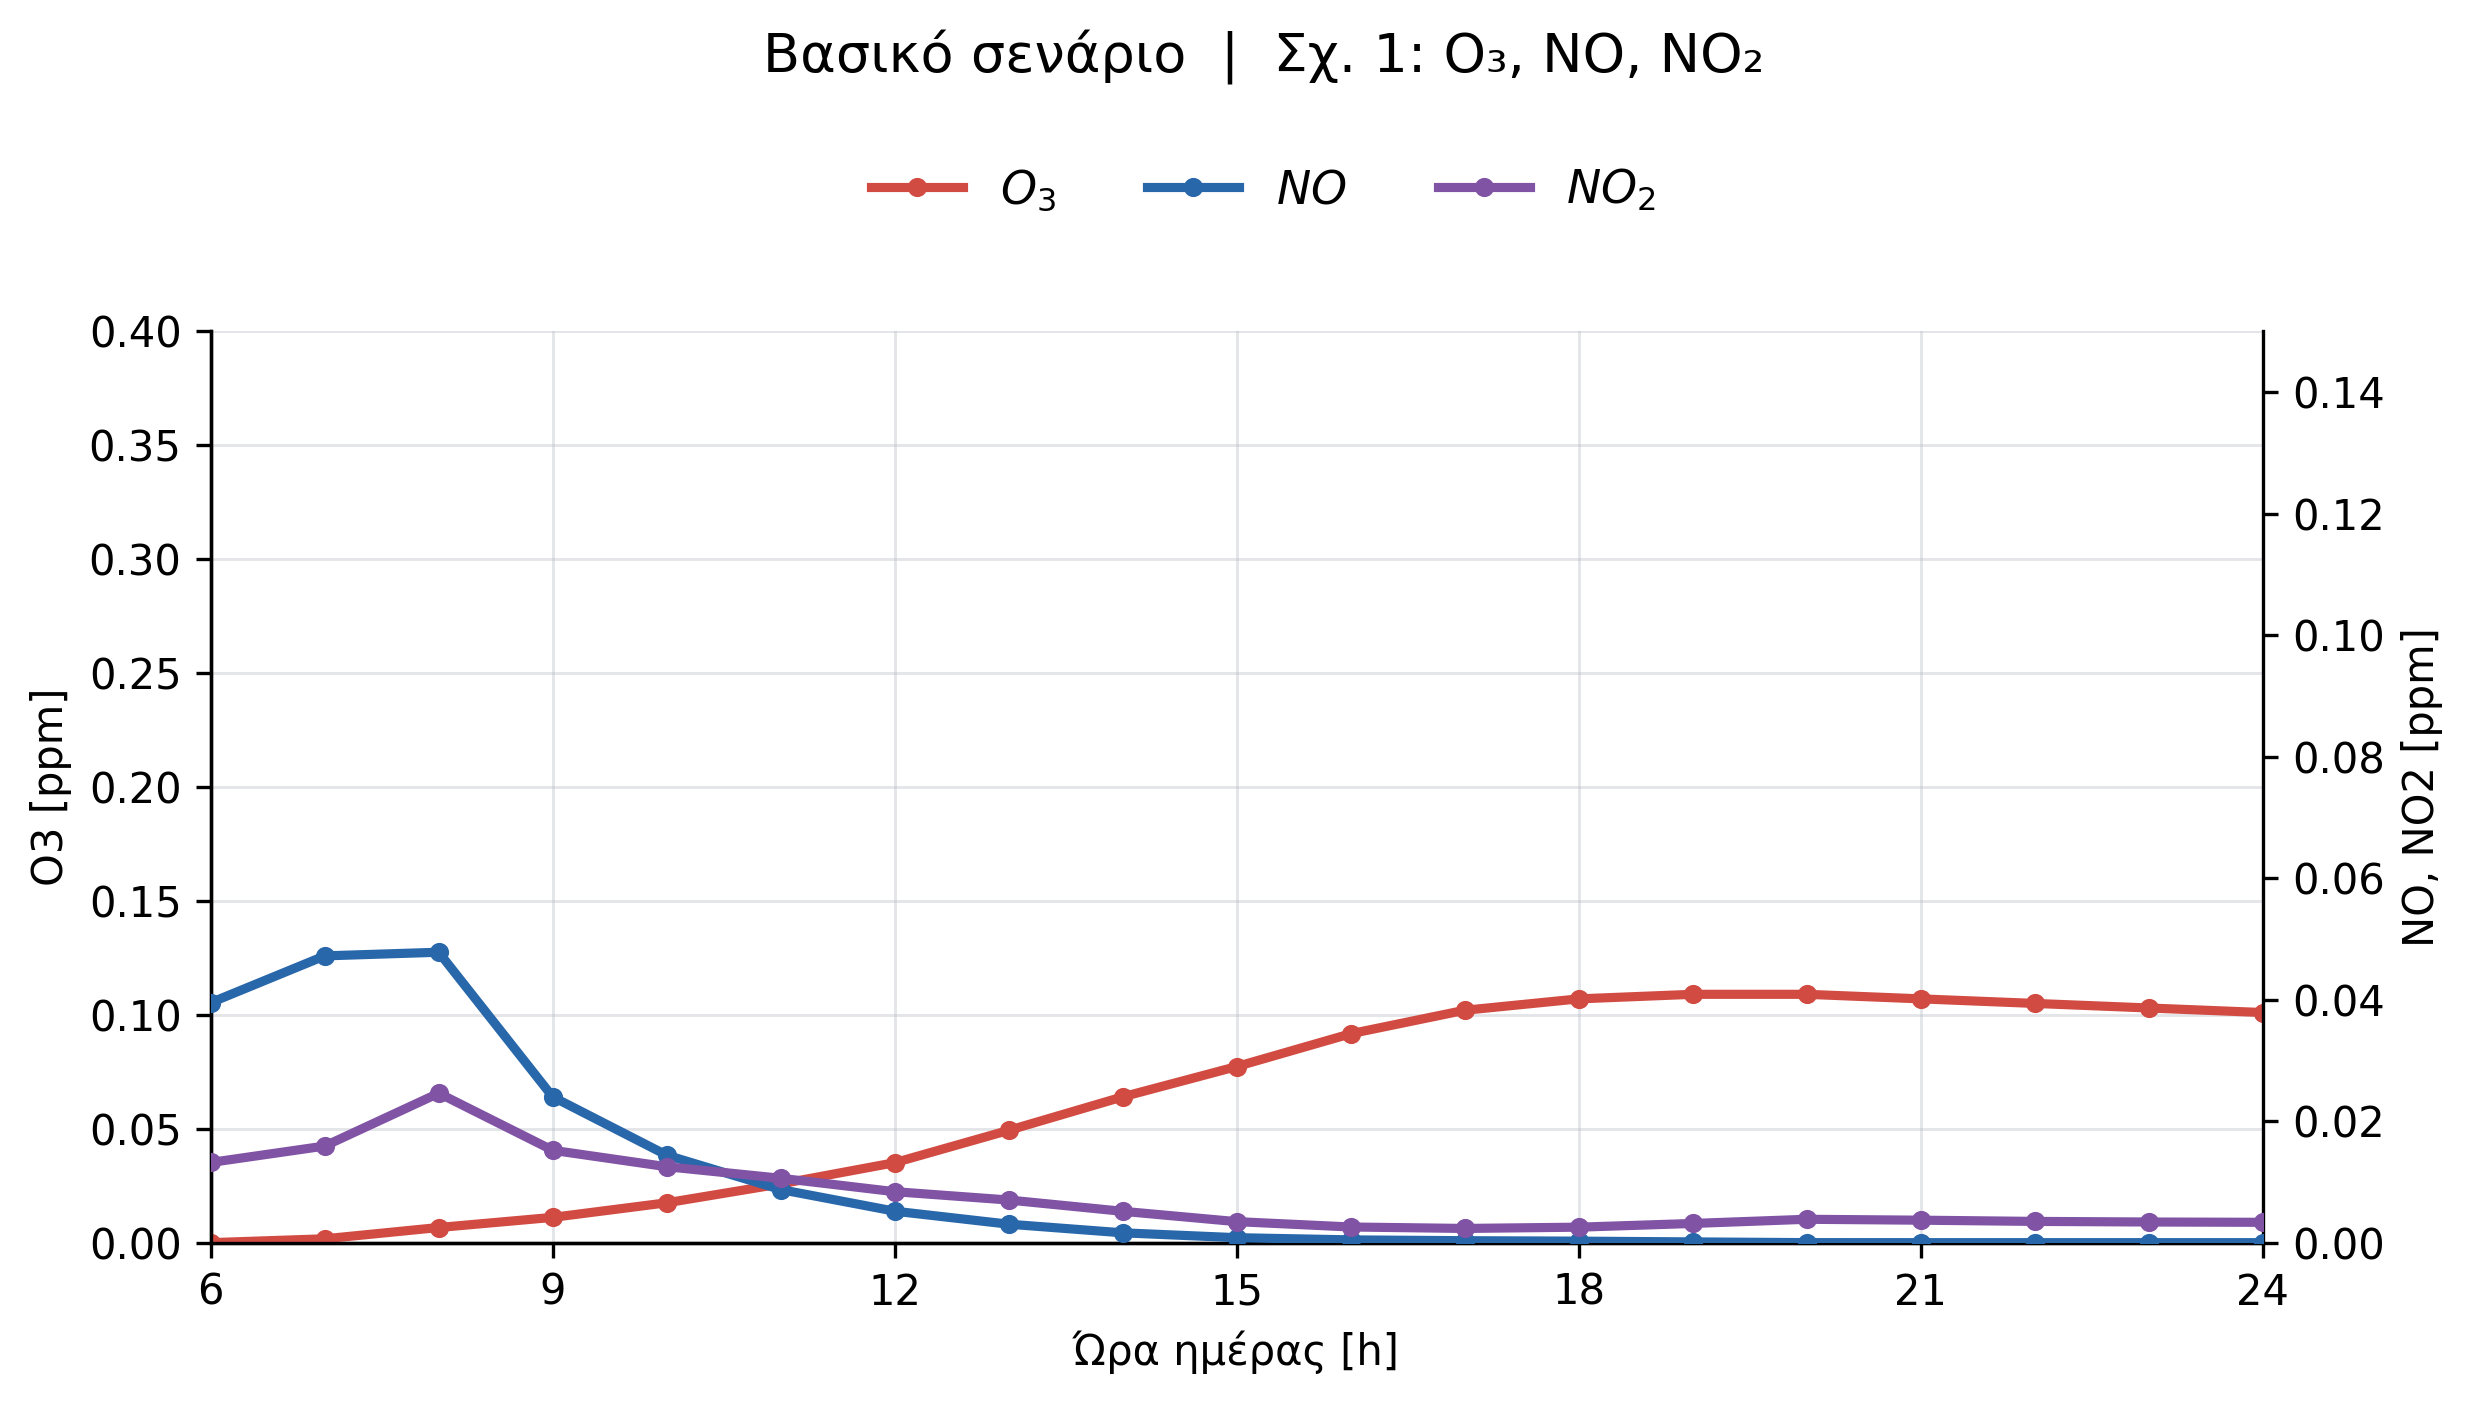

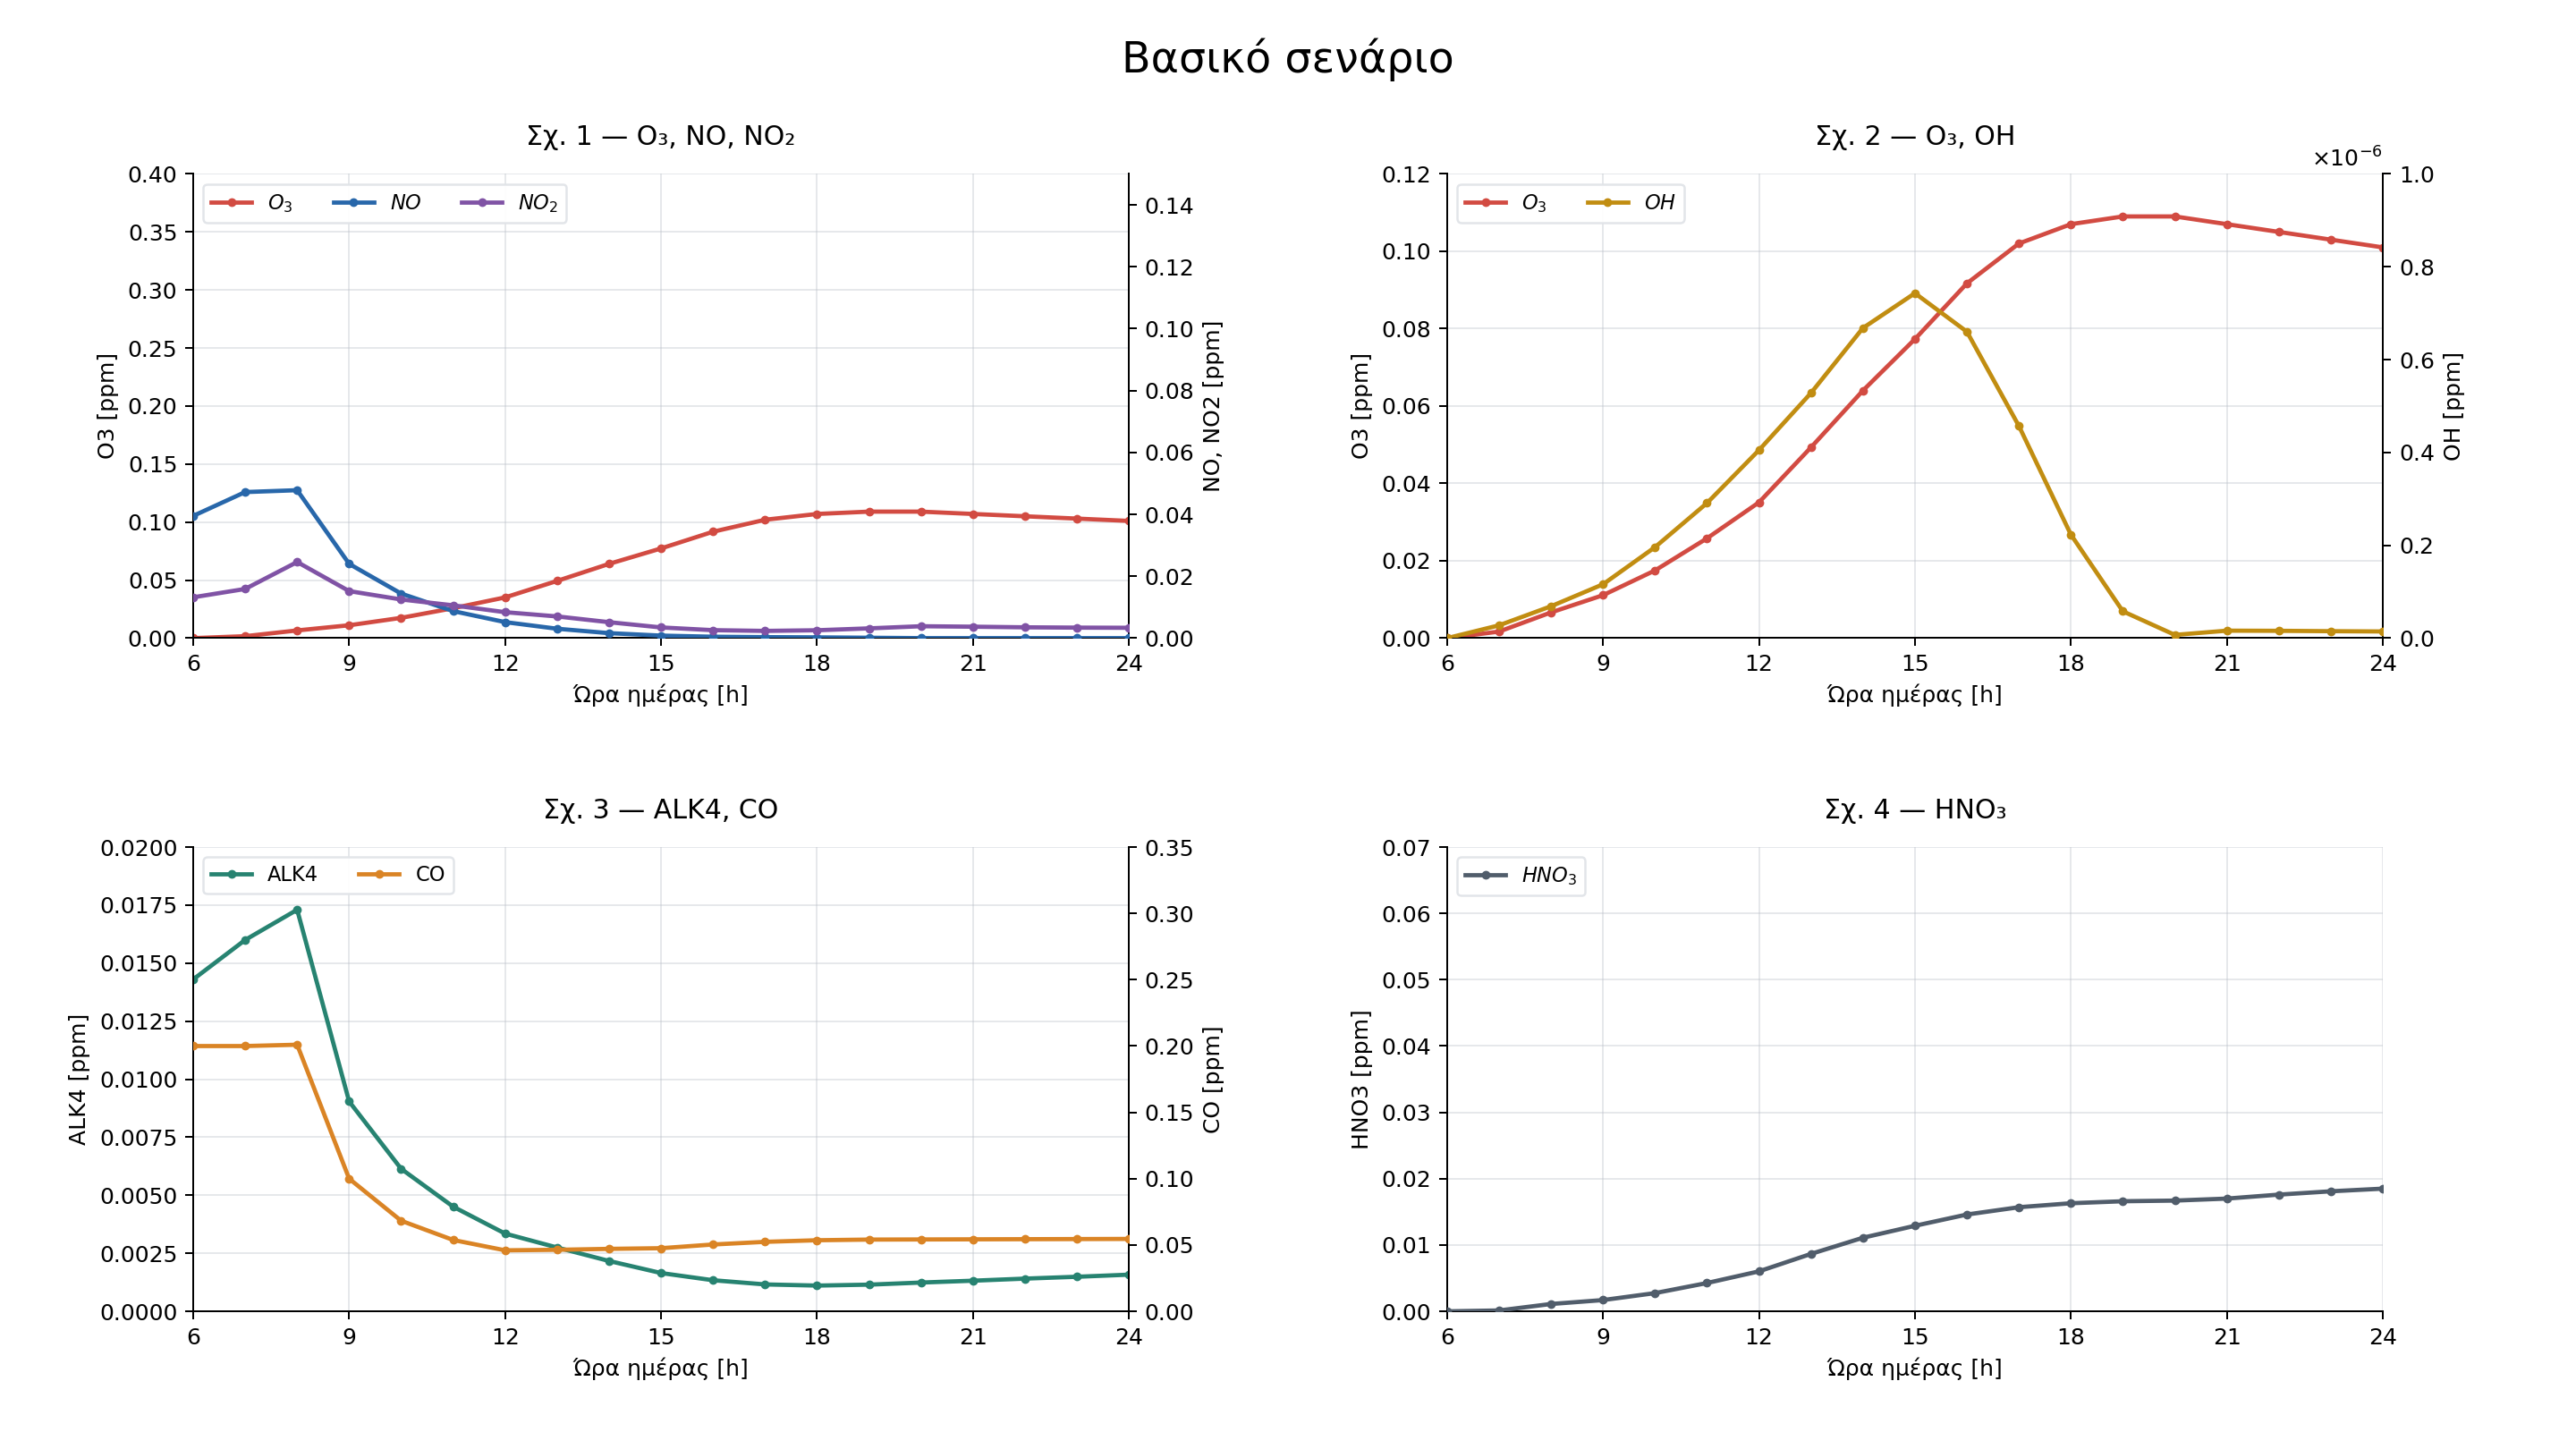

In [ ]:
display(Image(filename=str(FIGURES_DIR / "baseline_Fig1.png"), width=820))
if MAKE_SLIDE_PANELS:
    display(Image(filename=str(SLIDES_DIR / "slide_baseline.png"), width=980))

---

### Λίστα τελικού ελέγχου

- [x] 8 διαθέσιμα σενάρια, 18 υποχρεωτικά σχήματα.
- [x] Ίδια χρονική κλίμακα, 06:00–24:00, και κοινά όρια ανά τύπο σχήματος.
- [x] Δευτερεύων άξονας σε Σχ. 1, 2 και 3.
- [x] Ξεχωριστό HNO₃ στο Σχ. 4.
- [x] Προαιρετική σύγκριση O₃ και 8 έτοιμες εικόνες διαφανειών.
- [ ] Επιβεβαίωση ότι `HN 0` είναι το run `HV = 0`.
- [ ] Διευκρίνιση/παραλαβή του run Mixing Layer 800 m, εφόσον ζητείται και αυτό.
- [ ] Επιβεβαίωση ppm από τις ρυθμίσεις του αρχικού Box Model.

Η εργασία ζητά μία διαφάνεια ανά σενάριο και παράδοση έως Τρίτη 17/11/2026, 18:00 (από το PDF της εκφώνησης).

In [ ]:
import os
import shutil
from google.colab import files

output_folder = "Box_Model_Group1_Output"   # your folder with all plots
zip_name = "Box_Model_Group1_Output_all"

# make one zip from the whole folder
shutil.make_archive(zip_name, "zip", output_folder)

# download automatically to your PC
files.download(f"{zip_name}.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>